#### Aim: To choose a cambered airfoil NACA-abcd. For a given number of points on the airfoil geometry (N), reconstruct a smooth airfoil surface.


###### Using a random number generator to create NACA-abcd Airfoil.

In [88]:
#generating 3 random numbers for the NACA airfoil
import numpy as np

Max_camber = np.random.randint(2,10)
Max_c_location = np.random.randint(3,7)
Thickness = np.random.randint(10,15)

#print(Max_camber,Max_c_location,Thickness)

Max_camber = Max_camber/100
Max_c_location = Max_c_location/10
Thickness = Thickness/100

print(Max_camber,Max_c_location,Thickness)

#For ease of use
m = Max_camber
p = Max_c_location
t = Thickness

0.04 0.3 0.14


In [89]:
# writing a function to plot a Cambered NACA Airfoil

x = np.linspace(0, 1, 201) #creating n points for the x axis
#print(x)

# Corresponding y values for the generated x values.
y_t = 5*t*(0.2969*(x**0.5) - 0.1260*(x) - 0.3516*(x**2) + 0.2843*(x**3) - 0.1036*(x**4)) # y_t is thickness value

# evaluating y values for the x to plot the camber line
y_c = np.where(x <= p, (m/p**2) * (2*p*x - x**2), (m/(1-p)**2) * ((1 - 2*p) + 2*p*x - x**2))
#print(y_c)

# Evaluating x,y values for the upper and lower surfaces.
# So that the increment in y value due to the camber is perpendicular to the surface and not just along the y-axis 
d_yc = np.where(x <= p, (2*m/p**2) * (p - x),(2*m/(1-p)**2) * (p - x) )

Theta = np.arctan(d_yc)

x_u = x - y_t*np.sin(Theta)
y_u = y_c + y_t*np.cos(Theta)
x_l = x + y_t*np.sin(Theta)
y_l = y_c - y_t*np.cos(Theta)
#print(x_u,x_l)

x_l = np.flip(x_l)
y_l = np.flip(y_l)
#print(x_l)
X = np.concatenate([x_u,x_l])
Y = np.concatenate([y_u,y_l])
print(X[0],X[201])
#print(X,Y)

0.0 1.0


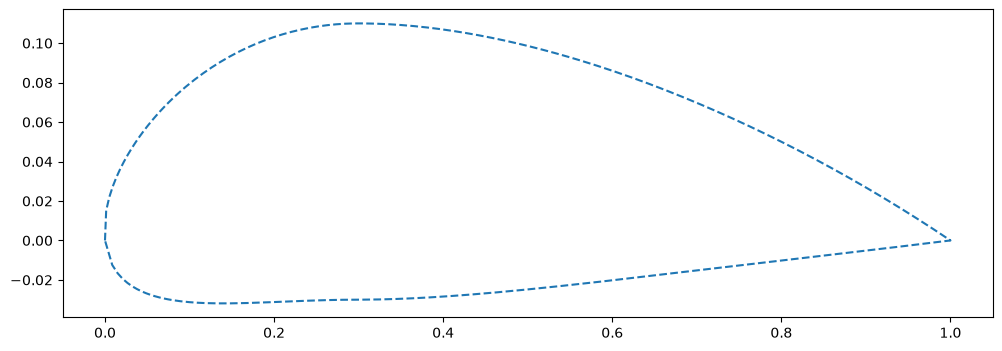

In [90]:

import matplotlib.pyplot as mp
mp.figure(figsize=(12, 4))
mp.plot(X,Y, '--')
mp.show()



In [91]:
#Writing a Lagrange function to perform interpolation
def Lagrng(x,y,n,a):
    sum = 0
    for i in range(0,n):
        product = y[i]
        for j in range(0,n):
            if i!= j:
                product = product*(a - x[j])/(x[i] - x[j])
        sum = sum + product
    return(sum)

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95 1.  ] [0.         0.05421455 0.07971865 0.09409919 0.10307479 0.10816437
 0.11000824 0.10933436 0.10690752 0.10326042 0.09858359 0.09284492
 0.08602042 0.07824443 0.06973119 0.06047882 0.05004359 0.03806401
 0.02672394 0.0269685  0.07102862]


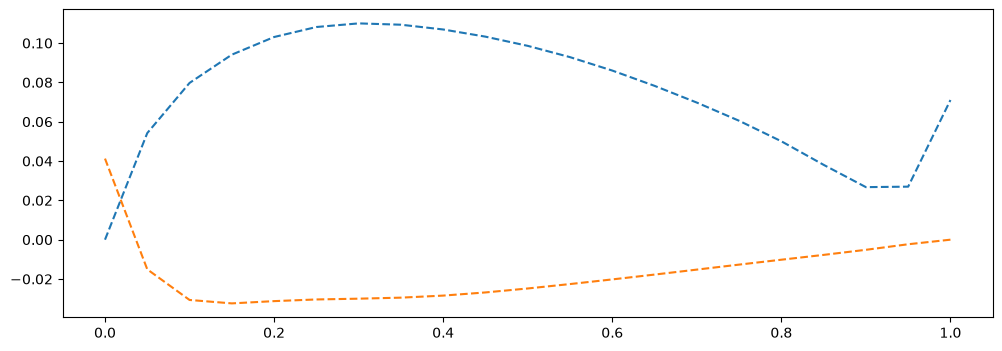

In [108]:
#x_u = np.array([X[0],X[10],X[20],X[30],X[40],X[60],X[80],X[100],X[120],X[140],X[180],X[200]])
#y_u = np.array([Y[0],Y[10],Y[20],Y[30],Y[40],Y[60],Y[80],Y[100],Y[120],Y[140],Y[180],Y[200]])

#x_l = np.array([X[201],X[220],X[250],X[275],X[300],X[325],X[350],X[375],X[380],X[390],X[400],X[401]])
#y_l = np.array([Y[201],Y[220],Y[250],Y[275],Y[300],Y[325],Y[350],Y[375],Y[380],Y[390],Y[400],Y[401]])

x_u = X[np.arange(0,200,20)]
y_u = Y[np.arange(0,200,20)]
x_l = X[np.arange(201,401,20)]
y_l = Y[np.arange(201,401,20)]

Xu= np.linspace(0,1,21)
Xl= np.flip(Xu)

Yu= Lagrng(x_u,y_u,10,Xu)
Yl= Lagrng(x_l,y_l,10,Xl)

#X_a= np.concatenate([Xu,Xl])
#Y_a= np.concatenate([Yu,Yl])
mp.figure(figsize=(12, 4))
mp.plot(Xu,Yu,'--')
mp.plot(Xl, Yl,'--')
print(Xu,Yu)
#print(Y_a)

X_test= np.concatenate([x_u,x_l])
Y_test= np.concatenate([y_u,y_l])
#mp.plot(X_test,Y_test)
#mp.plot(x_u,y_u,'o')

In [106]:
x_u


array([0.        , 0.09043755, 0.19407353, 0.3       , 0.40110457,
       0.5020127 , 0.6025952 , 0.70276261, 0.80244094, 0.90155262])